# 09 · Leakage check: what if the five main chemicals are allowed?

**Why this notebook exists.** In the AML viva, sir said the five chemicals that matter most (ammonia, BOD, orthophosphate, nitrogen, nitrate) could have been kept as inputs, since they matter more and the other inputs are not needed. We kept them out on purpose. This notebook measures what happens if we do not, so we can answer with numbers.

| | |
|---|---|
| **Input** | `data/processed/final_dataset.csv`, same station split and seed 42 |
| **Models** | the tuned XGBoost settings from Phase 1 and the tuned MLP from Phase 2, nothing re-tuned |
| **Evaluated on** | the **validation** set only. The test set is not touched |
| **Output** | `results/dl/leakage_check_validation.csv`, `results/dl/figures/five_driver_leakage_check.png` |

**Why it is a leakage check and not a new main model.** The CCME score is calculated from 8 measurements, and these five are most of them. A model that sees them can re-learn the formula, so both models should score near-perfectly and become impossible to tell apart. The project brief asks us to acknowledge this, and this notebook does it for the neural network as well.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

from src.features import (load_final_dataset, make_features, NUMERIC_COLS, CATEGORICAL_COLS,
                          HELD_OUT_COLS, TARGET_COL)
from src.train_dl import train_one, predict
from src.reproducibility import SEED

df = make_features(load_final_dataset("../data/processed/final_dataset.csv"))
parts = {k: df[df["split"] == k] for k in ("train", "val")}
print({k: len(v) for k, v in parts.items()}, "| five chemicals:", HELD_OUT_COLS)
print("share of missing values in the five chemicals (train):")
print(parts["train"][HELD_OUT_COLS].isna().mean().round(3).to_string())

{'train': 181747, 'val': 26054} | five chemicals: ['ammonia_mg_l', 'bod_mg_l', 'orthophosphate_mg_l', 'nitrogen_mg_l', 'nitrate_mg_l']
share of missing values in the five chemicals (train):
ammonia_mg_l           0.303
bod_mg_l               0.523
orthophosphate_mg_l    0.057
nitrogen_mg_l          0.066
nitrate_mg_l           0.235


## 1. Three input sets

| Set | Inputs |
|---|---|
| **A. Our design** | dissolved oxygen, pH, temperature, month, history, water type, country (the 30 columns the MLP uses) |
| **B. Five chemicals only** | ammonia, BOD, orthophosphate, nitrogen, nitrate. This is what sir suggested: keep these, drop the rest |
| **C. A + B** | everything |

Everything else is identical: median filling and scaling are fitted on training rows only, same splits, same seed, same tuned settings.

In [2]:
SETS = {
    "A. Our design (cheap sensors + context)": (NUMERIC_COLS, CATEGORICAL_COLS),
    "B. Five chemicals only":                  (HELD_OUT_COLS, []),
    "C. Our design + five chemicals":          (NUMERIC_COLS + HELD_OUT_COLS, CATEGORICAL_COLS),
}

def prepare(num, cat):
    steps = [("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]
    tf = [("num", Pipeline(steps), num)] + ([("cat", OneHotEncoder(handle_unknown="ignore"), cat)] if cat else [])
    prep = ColumnTransformer(tf)
    cols = num + cat
    Xtr = prep.fit_transform(parts["train"][cols]).astype(np.float32)      # fitted on training rows only
    Xva = prep.transform(parts["val"][cols]).astype(np.float32)
    return dict(X_train=Xtr, y_train=parts["train"][TARGET_COL].to_numpy(np.float32),
                X_val=Xva, y_val=parts["val"][TARGET_COL].to_numpy(np.float32))

def scores(y, p):
    p = np.clip(p, 0, 100)
    return dict(mae=mean_absolute_error(y, p), rmse=float(np.sqrt(mean_squared_error(y, p))), r2=r2_score(y, p))

MLP_CFG = dict(widths=(128, 64), dropout=0.2, weight_decay=1e-4, batch_norm=False, lr=1e-3, loss="mse", batch_size=512)
XGB_PARAMS = dict(n_estimators=300, max_depth=8, learning_rate=0.03, objective="reg:squarederror", subsample=0.8,
                  colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, n_jobs=-1, tree_method="hist", verbosity=0)

rows = []
for name, (num, cat) in SETS.items():
    data = prepare(num, cat)
    xgb = XGBRegressor(**XGB_PARAMS).fit(data["X_train"], data["y_train"])
    rows.append(dict(input_set=name, model="XGBoost", n_inputs=data["X_train"].shape[1],
                     **scores(data["y_val"], xgb.predict(data["X_val"]))))
    mlp, ym, ys, best_epoch, _ = train_one(data, MLP_CFG)
    rows.append(dict(input_set=name, model="MLP", n_inputs=data["X_train"].shape[1], best_epoch=best_epoch,
                     **scores(data["y_val"], predict(mlp, data["X_val"], ym, ys))))
    print("done:", name)

res = pd.DataFrame(rows)
res.round(4)

done: A. Our design (cheap sensors + context)


done: B. Five chemicals only


done: C. Our design + five chemicals


,input_set,model,n_inputs,mae,rmse,r2,best_epoch
0,A. Our design (cheap sensors + context),XGBoost,30,7.7064,11.1972,0.3487,NaN
1,A. Our design (cheap sensors + context),MLP,30,7.6737,11.2180,0.3463,33.0
2,B. Five chemicals only,XGBoost,10,0.5315,1.7098,0.9848,NaN
3,B. Five chemicals only,MLP,10,0.9065,1.8942,0.9814,31.0
4,C. Our design + five chemicals,XGBoost,40,0.3114,1.3238,0.9909,NaN
5,C. Our design + five chemicals,MLP,40,0.7538,1.6313,0.9862,49.0


## 2. Results (validation set)

Set A should reproduce the headline validation numbers from notebook 08 (MLP RMSE about 11.23, XGBoost about 11.20). If it does, the comparison with B and C is fair.

In [3]:
os.makedirs("../results/dl/figures", exist_ok=True)
res.to_csv("../results/dl/leakage_check_validation.csv", index=False)
show = res.pivot(index="input_set", columns="model", values=["rmse", "r2"]).round(3)
show

rmse             r2        
model                                       MLP XGBoost    MLP XGBoost
input_set                                                             
A. Our design (cheap sensors + context)  11.218  11.197  0.346   0.349
B. Five chemicals only                    1.894   1.710  0.981   0.985
C. Our design + five chemicals            1.631   1.324  0.986   0.991

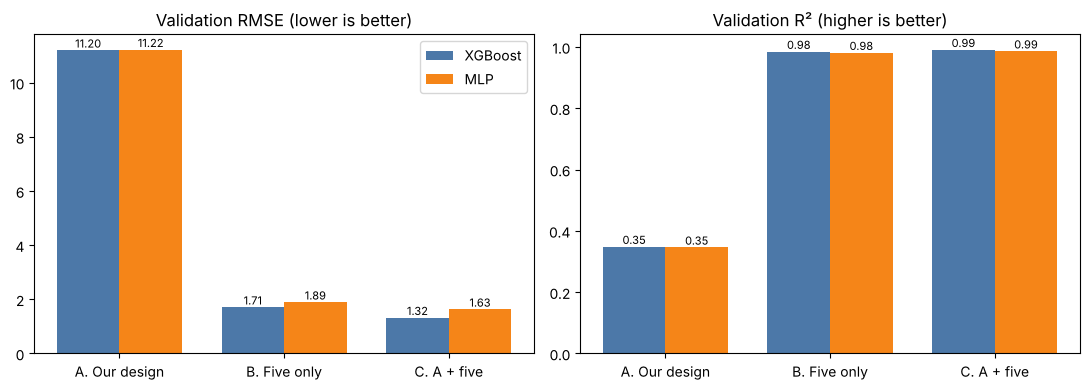

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = ["A. Our design", "B. Five only", "C. A + five"]
x = np.arange(3); w = 0.38
for ax, metric, title in zip(axes, ["rmse", "r2"], ["Validation RMSE (lower is better)", "Validation R² (higher is better)"]):
    for k, (m, col) in enumerate([("XGBoost", "#4C78A8"), ("MLP", "#F58518")]):
        vals = res[res.model == m][metric].to_numpy()
        ax.bar(x + (k - 0.5) * w, vals, w, label=m, color=col)
        for xi, v in zip(x + (k - 0.5) * w, vals):
            ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_title(title)
axes[0].legend()
plt.tight_layout()
plt.savefig("../results/dl/figures/five_driver_leakage_check.png", dpi=160)
plt.show()

## 3. What this shows

Validation set, station split, tuned settings, nothing re-tuned.

| Inputs | XGBoost RMSE (R²) | MLP RMSE (R²) |
|---|---|---|
| A. Our design (cheap sensors + context) | 11.20 (0.349) | 11.22 (0.346) |
| B. Five chemicals only | 1.71 (0.985) | 1.89 (0.981) |
| C. A + five chemicals | 1.32 (0.991) | 1.63 (0.986) |

- **Sir's suggestion works, almost too well.** With the five chemicals the typical error drops from about 11 points to under 2, and R² goes from about 0.35 to about 0.98. That is not a better model, it is the model re-learning the formula the score is calculated from.
- **The comparison stops being informative.** Both models land within about 0.2 to 0.3 RMSE of each other at a tiny error, so there is nothing left to learn about trees versus networks. This is why the main experiments keep the five chemicals out.
- **The trade-off is cost.** Set A needs only dissolved oxygen, pH and temperature (cheap sensors). Sets B and C need ammonia, BOD, orthophosphate, nitrogen and nitrate, which are lab tests. Our design asks the harder, more useful question: how well can the score be estimated *without* the expensive tests?
- Set A reproduces the headline validation numbers (11.20 and 11.22, against 11.205 and 11.231 in notebook 08). The small differences are run-to-run variation in a separate training run, not a change of method.
- Validation only. The test set was not used here.